# ProteinBursty model demo

This notebook demonstrates the **ProteinBursty** model — a three-species extension
of the Bursty model that tracks unspliced RNA, spliced RNA, and protein jointly.

| Parameter | Symbol | Meaning |
|---|---|---|
| Burst size | *b* | Mean number of transcripts per burst |
| mRNA degradation | *β* | Degradation rate of unspliced mRNA |
| Splicing rate | *γ* | Splicing / mature mRNA degradation rate |
| Protein production | *k_p* | Translation rate |
| Protein degradation | *γ_p* | Protein degradation rate |

**Note:** Each PSS evaluation takes ~2 s on CPU (the ODE is integrated per grid point).
Fitting runs Nelder-Mead for ~100 evaluations ≈ 3–4 minutes total.


In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import sys, os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import anndata as ad
import time

from monod.cme_toolbox import CMEModel
from monod.extract_data import extract_data

# Check which backends are active
from monod.cme_toolbox import _HAS_RUST, _HAS_GPU
os.makedirs('figures', exist_ok=True)
print(f'Rust backend: {_HAS_RUST}')
print(f'GPU  backend: {_HAS_GPU}')

Rust backend: True
GPU  backend: False


---
## 1 · Load data

The bundled `example_adata.h5ad` contains ~66 k cells with unspliced, spliced,
and **protein** layers for gene **PTPRC**.

Cells  : 65,988
Genes  : 1
Layers : ['ambiguous', 'mature', 'nascent', 'protein', 'spliced', 'unspliced']

PTPRC — mean counts:
  unspliced : 1.42  (max 71)
  spliced   : 0.62  (max 34)
  protein   : 0.20  (max 76)


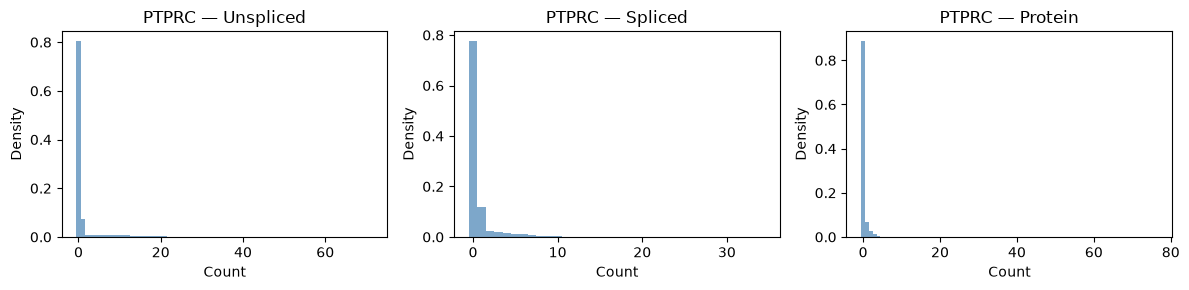

In [3]:
import scipy.sparse as sp

EXAMPLE_PATH = os.path.join('example_h5ad', 'example_adata.h5ad')
raw_adata = ad.read_h5ad(EXAMPLE_PATH)

print(f'Cells  : {raw_adata.n_obs:,}')
print(f'Genes  : {raw_adata.n_vars}')
print(f'Layers : {list(raw_adata.layers.keys())}')

def _dense(arr):
    return np.asarray(arr.todense()).ravel() if sp.issparse(arr) else np.asarray(arr).ravel()

gene = 'PTPRC'
u = _dense(raw_adata.layers['unspliced'][:, 0]).astype(int)
s = _dense(raw_adata.layers['spliced'][:, 0]).astype(int)
p = _dense(raw_adata.layers['protein'][:, 0]).astype(int)

print(f'\n{gene} — mean counts:')
print(f'  unspliced : {u.mean():.2f}  (max {u.max()})')
print(f'  spliced   : {s.mean():.2f}  (max {s.max()})')
print(f'  protein   : {p.mean():.2f}  (max {p.max()})')

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, counts, label in zip(axes, [u, s, p], ['Unspliced', 'Spliced', 'Protein']):
    ax.hist(counts, bins=np.arange(counts.max() + 2) - 0.5, density=True, color='steelblue', alpha=0.7)
    ax.set_xlabel('Count'); ax.set_ylabel('Density')
    ax.set_title(f'{gene} — {label}')
plt.savefig('figures/protein_bursty_data.png', dpi=150, bbox_inches='tight')
plt.tight_layout(); plt.show()

---
## 2 · Preprocess with `extract_data`

`protein_limit=20` coarsens the protein axis of the PGF grid, reducing evaluation
time ~5× at the cost of slight approximation error.

PTPRC has low mean protein expression (< 1), so we pass `genes_to_fit` to bypass
the expression filter.

In [4]:
pb_model = CMEModel('ProteinBursty', 'None', protein_limit=20)

proc_adata = extract_data(
    raw_adata,
    pb_model,
    dataset_name='demo_protein_bursty',
    n_genes=1,
    viz=False,
    hist_type='unique',
    genes_to_fit=list(raw_adata.var_names),   # bypass expression filter
)

import sys
from monod.inference import searchdata_from_adata

M3 = proc_adata.uns['M'][:, 0].tolist()
search_data3 = searchdata_from_adata(proc_adata)
coords3, freqs3 = search_data3.hist[0]

print(f'Grid limits (unspliced, spliced, protein): {M3}')
print(f'Unique histogram points: {len(coords3)}')
print(f'Modalities: {list(proc_adata.uns["modality_name_dict"].keys())}')

/home/coakes/monod/src/monod/extract_data.py:1004: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  gene_exp_filter[gene_loc[0]] = False  # Exclude from sampling pool
0 random genes selected: cannot satisfy query of 0 genes.


Grid limits (unspliced, spliced, protein): [81, 44, 86]
Unique histogram points: 1696
Modalities: ['unspliced', 'spliced', 'protein']


---
## 3 · Method-of-Moments initial estimate

`get_MoM` uses empirical moments to compute a fast closed-form starting point.
ProteinBursty has 5 parameters: *b*, *β*, *γ*, *k_p*, *γ_p*.

In [5]:
mom3 = {col: float(proc_adata.var[col].values[0])
        for col in proc_adata.var.columns if col.startswith('MOM_')}

lb3 = np.array(pb_model.bio_bounds['phys_lb'])
ub3 = np.array(pb_model.bio_bounds['phys_ub'])

p3_mom = pb_model.get_MoM(mom3, lb3, ub3, samp=np.zeros(2))

param_names_pb = ['log₁₀ b', 'log₁₀ β', 'log₁₀ γ', 'log₁₀ k_p', 'log₁₀ γ_p']
print('MoM parameter estimates (log₁₀ scale):')
for name, val in zip(param_names_pb, p3_mom):
    print(f'  {name} = {val:.3f}  →  {10**val:.4f}')

# Evaluate PSS and KLD at MoM
t0 = time.perf_counter()
pss3_mom = pb_model.eval_model_pss(p3_mom, M3)
print(f'\nPSS evaluation time: {time.perf_counter()-t0:.2f} s')
kld3_mom = pb_model.eval_model_kld(p3_mom, M3, None, (coords3, freqs3))
print(f'KLD at MoM: {kld3_mom:.5f}')

MoM parameter estimates (log₁₀ scale):
  log₁₀ b = 1.110  →  12.8737
  log₁₀ β = 0.957  →  9.0654
  log₁₀ γ = 1.317  →  20.7365
  log₁₀ k_p = 1.359  →  22.8814
  log₁₀ γ_p = 1.847  →  70.3634

PSS evaluation time: 0.08 s
KLD at MoM: 2.10480


---
## 4 · Visualise the 3D distribution — pairwise projections

Since the PSS lives in a 3D grid (unspliced × spliced × protein), we plot
the three pairwise 2D marginals, with observed data overlaid as a scatter.

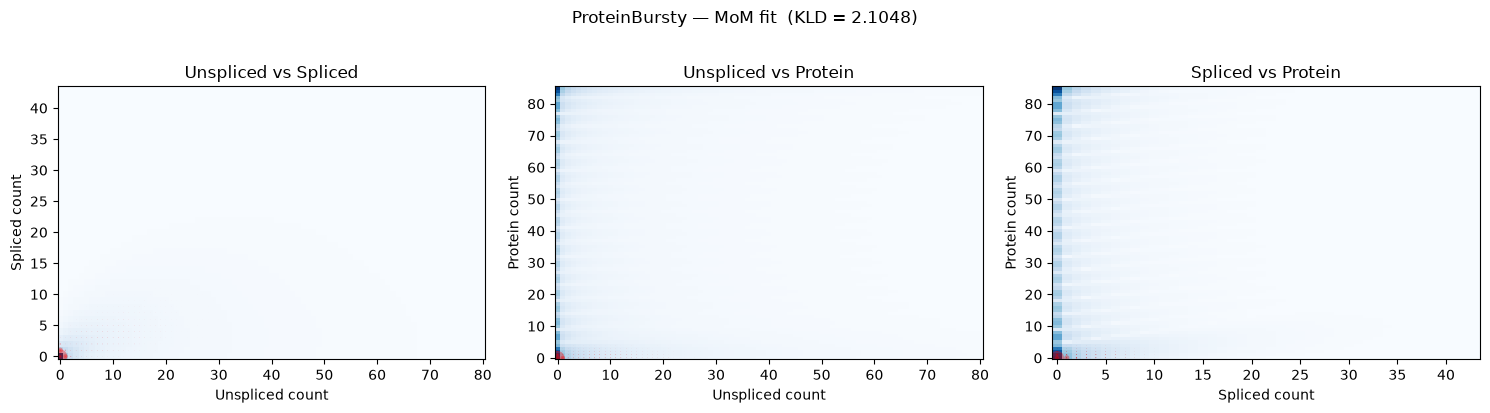

In [6]:
def plot_3d_projections(pss3, coords3, freqs3, M3, title):
    """Three pairwise marginal projections of a 3D PSS."""
    labels = ['Unspliced', 'Spliced', 'Protein']
    pairs  = [(0, 1), (0, 2), (1, 2)]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (i, j) in zip(axes, pairs):
        # Sum over the third axis
        third = [k for k in range(3) if k not in (i, j)][0]
        pss2 = pss3.sum(axis=third)
        if i > j:                      # ensure (row=j, col=i) orientation
            pss2 = pss2.T
        ax.imshow(pss2.T, origin='lower', aspect='auto', cmap='Blues',
                  norm=mcolors.PowerNorm(gamma=0.4, vmin=0),
                  extent=[-0.5, M3[i]-0.5, -0.5, M3[j]-0.5])
        ax.scatter(coords3[:, i], coords3[:, j],
                   s=freqs3 * 150, c='red', alpha=0.35, linewidths=0)
        ax.set_xlabel(f'{labels[i]} count'); ax.set_ylabel(f'{labels[j]} count')
        ax.set_title(f'{labels[i]} vs {labels[j]}')
    fig.suptitle(title, y=1.02, fontsize=12)
    plt.savefig('figures/protein_bursty_pss3d.png', dpi=150, bbox_inches='tight')
    plt.tight_layout(); plt.show()

plot_3d_projections(pss3_mom, coords3, freqs3, M3,
                    f'ProteinBursty — MoM fit  (KLD = {kld3_mom:.4f})')

---
## 5 · Optimisation

We minimise the KLD two ways from the same method-of-moments start:

1. **L-BFGS-B** with `eval_model_kld_and_grad`, which returns the KLD and its
   gradient in one call.  With `monod_core` installed the forward-difference
   stencil is evaluated in Rust, with every stencil point integrated on the base
   point's time grid, so the gradient is smooth in the parameters even though
   the ODE step count changes discretely with them.
2. **Nelder-Mead**, gradient-free, for comparison.

The comparison is instructive.  With protein counts coarse-grained
(`protein_limit=20`), the protein production and degradation rates
$k_p$ and $\gamma_p$ are only weakly identified individually: the likelihood
has a long, nearly flat valley along which they trade off.  A gradient method
stops as soon as progress along the valley falls below its tolerance, while
Nelder-Mead's large exploratory steps carry it further along it.  Restarting
L-BFGS-B from the Nelder-Mead point reaches a lower KLD still (2.0699 on this
gene), but is not run here: in that region the rate constants are spread
further apart, so each steady-state evaluation needs many more integration
steps and the polish takes about fifteen minutes.  In practice this is what
`num_restarts` and the MoM-plus-random restart pattern in
`InferenceParameters` are for.


In [7]:
from scipy.optimize import minimize

M3_list = [int(m) for m in M3]
data3 = (coords3, freqs3)
bounds3 = list(zip(lb3, ub3))
n3_evals = {'lbfgsb': 0, 'nm': 0}

def kld_and_grad(p_log, key):
    n3_evals[key] += 1
    return pb_model.eval_model_kld_and_grad(p_log, M3_list, None, data3)

def kld_only(p_log):
    n3_evals['nm'] += 1
    return pb_model.eval_model_kld(p_log, M3_list, None, data3)

opts_lbfgsb = {'maxiter': 200, 'ftol': 1e-10, 'gtol': 1e-6}

t0 = time.perf_counter()
res_lb = minimize(kld_and_grad, x0=p3_mom, args=('lbfgsb',), jac=True,
                  method='L-BFGS-B', bounds=bounds3, options=opts_lbfgsb)
t_lb = time.perf_counter() - t0

t0 = time.perf_counter()
res_nm = minimize(kld_only, x0=p3_mom, method='Nelder-Mead',
                  options={'maxiter': 100, 'xatol': 1e-3, 'fatol': 1e-4})
t_nm = time.perf_counter() - t0

print(f'{"stage":28s} {"KLD":>9s}  {"evals":>6s}  {"time":>6s}')
print(f'{"L-BFGS-B from MoM":28s} {res_lb.fun:9.5f}  {n3_evals["lbfgsb"]:6d}  {t_lb:5.1f}s   ({res_lb.nit} iterations)')
print(f'{"Nelder-Mead from MoM":28s} {res_nm.fun:9.5f}  {n3_evals["nm"]:6d}  {t_nm:5.1f}s')

best = min((res_lb, res_nm), key=lambda r: r.fun)
p3_opt, kld3_opt = best.x, best.fun

print(f'\nParameter comparison (log10 scale), best stage:')
for name, vm, vo in zip(param_names_pb, p3_mom, p3_opt):
    print(f'  {name:12s}: MoM = {vm:.3f}  ->  opt = {vo:.3f}  (delta = {vo-vm:+.3f})')
print(f'\nKLD  MoM -> opt:  {kld3_mom:.5f}  ->  {kld3_opt:.5f}'
      f'  (improvement {kld3_mom-kld3_opt:.5f})')


stage                              KLD   evals    time
L-BFGS-B from MoM              2.10185      39   10.0s   (20 iterations)
Nelder-Mead from MoM           2.09751     164    8.4s

Parameter comparison (log10 scale), best stage:
  log₁₀ b     : MoM = 1.110  ->  opt = 1.239  (delta = +0.129)
  log₁₀ β     : MoM = 0.957  ->  opt = 0.927  (delta = -0.030)
  log₁₀ γ     : MoM = 1.317  ->  opt = 1.259  (delta = -0.058)
  log₁₀ k_p   : MoM = 1.359  ->  opt = 0.473  (delta = -0.887)
  log₁₀ γ_p   : MoM = 1.847  ->  opt = 0.934  (delta = -0.913)

KLD  MoM -> opt:  2.10480  ->  2.09751  (improvement 0.00728)


---
## 6 · Visualise the optimised fit

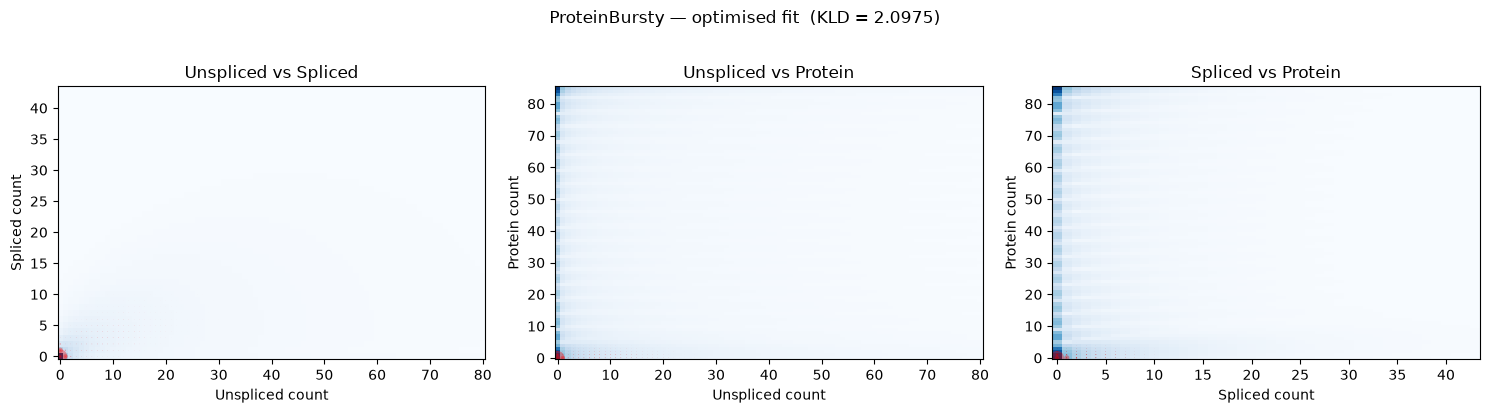

In [8]:
pss3_opt = pb_model.eval_model_pss(p3_opt, M3)
plot_3d_projections(pss3_opt, coords3, freqs3, M3,
                    f'ProteinBursty — optimised fit  (KLD = {kld3_opt:.4f})')

---
## 7 · MoM vs optimised — marginal comparison

Plot all three marginals side-by-side to see where the optimiser improved the fit.

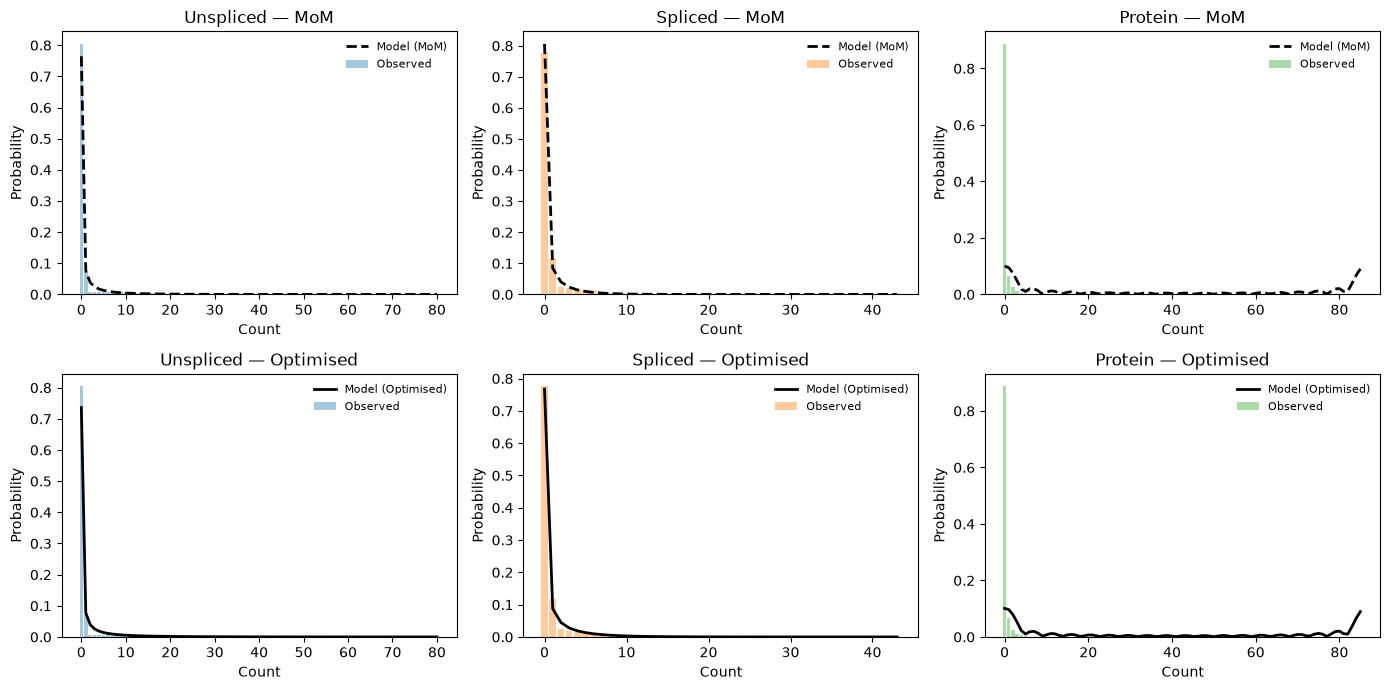

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
modality_labels = ['Unspliced', 'Spliced', 'Protein']
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Empirical marginals from the unique histogram
obs_marg = [np.zeros(M3[d]) for d in range(3)]
for pt, f in zip(coords3, freqs3):
    for d in range(3):
        if int(pt[d]) < M3[d]:
            obs_marg[d][int(pt[d])] += f

for col, (label, color) in enumerate(zip(modality_labels, colors)):
    obs = obs_marg[col]
    # sum over the other two axes
    pss_m_mom = pss3_mom.sum(axis=tuple(d for d in range(3) if d != col))
    pss_m_opt = pss3_opt.sum(axis=tuple(d for d in range(3) if d != col))

    for row, (ax, pss_m, fit_label, ls) in enumerate(zip(
            axes[:, col],
            [pss_m_mom, pss_m_opt],
            ['MoM', 'Optimised'],
            ['--', '-'])):
        ax.bar(np.arange(len(obs)), obs, color=color, alpha=0.4, label='Observed')
        ax.plot(np.arange(len(pss_m)), pss_m, 'k', lw=2,
                linestyle=ls, label=f'Model ({fit_label})')
        ax.set_xlabel('Count'); ax.set_ylabel('Probability')
        ax.set_title(f'{label} — {fit_label}')
        ax.legend(frameon=False, fontsize=8)

plt.savefig('figures/protein_bursty_fit.png', dpi=150, bbox_inches='tight')
plt.tight_layout(); plt.show()

---
## 8 · Fitted parameter interpretation

In [10]:
print('Fitted ProteinBursty parameters for PTPRC:')
print()
for name, val_log in zip(param_names_pb, p3_opt):
    val = 10**val_log
    print(f'  {name} = {val_log:.3f}  →  {val:.4f}')

b, beta, gamma, k_p, gamma_p = 10**p3_opt
print(f'\nDerived quantities:')
print(f'  Mean burst size          b       = {b:.2f}')
print(f'  mRNA half-life     ln2/β  = {np.log(2)/beta:.2f} a.u.')
print(f'  Splicing half-life  ln2/γ  = {np.log(2)/gamma:.2f} a.u.')
print(f'  Protein production rate k_p     = {k_p:.2f}')
print(f'  Protein half-life  ln2/γ_p= {np.log(2)/gamma_p:.2f} a.u.')
print(f'  Mean mRNA   ≈ b·β/(β·γ)       = {b*beta/(beta*gamma):.2f}')
print(f'  Mean protein ≈ k_p/γ_p        = {k_p/gamma_p:.2f}')

Fitted ProteinBursty parameters for PTPRC:

  log₁₀ b = 1.239  →  17.3203
  log₁₀ β = 0.927  →  8.4588
  log₁₀ γ = 1.259  →  18.1544
  log₁₀ k_p = 0.473  →  2.9696
  log₁₀ γ_p = 0.934  →  8.5936

Derived quantities:
  Mean burst size          b       = 17.32
  mRNA half-life     ln2/β  = 0.08 a.u.
  Splicing half-life  ln2/γ  = 0.04 a.u.
  Protein production rate k_p     = 2.97
  Protein half-life  ln2/γ_p= 0.08 a.u.
  Mean mRNA   ≈ b·β/(β·γ)       = 0.95
  Mean protein ≈ k_p/γ_p        = 0.35
